# Assignment 4 — Sequential Modeling with Recurrent Networks
**Course: Deep Learning**

| Task | Dataset | Sequence | Classes |
|---|---|---|---|
| 1 | Kannada-MNIST handwritten digits | 28 rows x 28 pixels (T = 28, x_t in R^28) | 10 |
| 2 | Spoken Arabic Digit (pre-computed MFCC) | variable T (4-93 frames), x_t in R^13 | 10 |

For both tasks the notebook tunes **number of recurrent layers**, **hidden units** and **cell type
(Vanilla RNN / LSTM / GRU)**, uses the **|L(k) - L(k-1)| < 1e-4** convergence rule (no fixed epoch count),
and then runs the bonus experiments (bidirectional networks, temporal attention pooling) and a
gradient-flow study.

**How to run:** put the data files in `./data/` (see the loader cells for the accepted file names) and
run all cells. Everything is CPU-friendly; a GPU is used automatically when available.

## 0. Setup

In [ ]:
import os, time, json, copy, itertools, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from sklearn.metrics import confusion_matrix, classification_report

DATA_DIR, FIG_DIR, OUT_DIR = 'data', 'figs', 'out'
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3, 'font.size': 9})
print('torch', torch.__version__, '| device:', DEVICE)

torch 2.14.1+cu130 | device: cpu


## 1. Common building blocks
### 1.1 Model
One class covers every architecture in the assignment:
* `cell` in {`RNN` (tanh), `LSTM`, `GRU`}, `layers` stacked recurrent layers, `hidden` units per layer.
* `bidirectional=True` -> bonus bidirectional network.
* `attention=False` -> the sequence is summarised by the **final hidden state** of the top layer
  (for variable-length input this is the state at the **true last frame**, never a padding frame).
* `attention=True` -> bonus **temporal attention pooling**:
  `e_t = v^T tanh(W h_t)`, `a = softmax(e)` over valid timesteps, `c = sum_t a_t h_t`.

In [ ]:
class SeqClassifier(nn.Module):
    def __init__(self, in_dim, hidden, layers, cell='LSTM', n_classes=10,
                 bidirectional=False, attention=False):
        super().__init__()
        rnn_cls = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[cell]
        self.rnn = rnn_cls(in_dim, hidden, num_layers=layers, batch_first=True,
                           bidirectional=bidirectional)
        self.cell, self.layers, self.hidden = cell, layers, hidden
        self.dirs = 2 if bidirectional else 1
        self.attention = attention
        d = hidden * self.dirs
        if attention:
            self.att_W = nn.Linear(d, d)
            self.att_v = nn.Linear(d, 1, bias=False)
        self.fc = nn.Linear(d, n_classes)
        self.last_att = None

    def forward(self, x, lengths=None):
        # x: (B, T, D); lengths: (B,) true lengths or None when all sequences have length T
        B, T, _ = x.shape
        use_pack = lengths is not None and self.dirs == 2
        if use_pack:
            # Bidirectional + variable length: packing is required so that the backward direction
            # starts at the true last frame instead of at the padding.
            packed = pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
            out, h = self.rnn(packed)
            out, _ = pad_packed_sequence(out, batch_first=True, total_length=T)
        else:
            out, h = self.rnn(x)
        if self.cell == 'LSTM':
            h = h[0]
        if lengths is not None and self.dirs == 1 and not self.attention:
            # Unidirectional + padded batch: a causal RNN's state at the true last frame (index len-1)
            # is unaffected by the padding that follows, so gathering it is exactly equivalent to
            # packing (and much faster on CPU).
            idx = (lengths.to(x.device) - 1).clamp(min=0)
            return self.fc(out[torch.arange(B, device=x.device), idx])
        if self.attention:
            e = self.att_v(torch.tanh(self.att_W(out))).squeeze(-1)          # (B, T)
            if lengths is not None:
                mask = torch.arange(T, device=x.device)[None, :] >= lengths.to(x.device)[:, None]
                e = e.masked_fill(mask, float('-inf'))
            a = torch.softmax(e, dim=1)
            self.last_att = a.detach()
            feat = (a.unsqueeze(-1) * out).sum(1)
        else:
            h = h.view(self.layers, self.dirs, B, self.hidden)[-1]           # top layer
            feat = torch.cat([h[d] for d in range(self.dirs)], dim=1)        # fwd-last (+ bwd-last)
        return self.fc(feat)

def count_params(m): return sum(p.numel() for p in m.parameters())

### 1.2 Training with the convergence criterion
* Loss = mean cross-entropy; "average training error" of an epoch = mean loss over all training samples of that epoch.
* **Stopping rule (as required):** stop at the first epoch k with `|L(k) - L(k-1)| < 1e-4`.
  No fixed epoch budget is used; `MAX_EPOCHS` is only a safety cap and the tables report whether it was hit.
* Optimiser: Adam with an exponentially decaying learning rate (x0.85 per epoch). The decay makes the
  epoch-to-epoch loss change shrink smoothly, so the 1e-4 rule fires in reasonable time on a CPU
  instead of being defeated by mini-batch noise.
* Gradient-norm clipping (max norm 5) for every model; the **pre-clipping** norm is logged every step
  and used later in the gradient-flow analysis.
* Identical optimiser settings for all cells so the comparison is fair.

In [ ]:
TOL, MAX_EPOCHS, LR, LR_GAMMA, CLIP = 1e-4, 60, 1e-3, 0.85, 5.0

def iterate(X, y, L, bs, shuffle):
    n = len(X); idx = torch.randperm(n) if shuffle else torch.arange(n)
    for i in range(0, n, bs):
        b = idx[i:i + bs]
        if L is None:
            yield X[b].to(DEVICE), y[b].to(DEVICE), None
        else:
            lb = L[b]; yield X[b][:, :int(lb.max())].to(DEVICE), y[b].to(DEVICE), lb

@torch.no_grad()
def evaluate(model, X, y, L=None, bs=1024):
    model.eval(); loss = 0.; preds = []
    for xb, yb, lb in iterate(X, y, L, bs, False):
        o = model(xb, lb); loss += F.cross_entropy(o, yb, reduction='sum').item()
        preds.append(o.argmax(1).cpu())
    preds = torch.cat(preds)
    return loss / len(X), (preds == y).float().mean().item(), preds.numpy()

def train_until_converged(model, tr, va, bs, tag=''):
    Xtr, ytr, Ltr = tr
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    sched = torch.optim.lr_scheduler.ExponentialLR(opt, LR_GAMMA)
    hist = dict(train_loss=[], val_loss=[], val_acc=[], grad_norm=[])
    prev, converged, t0 = None, False, time.time()
    for ep in range(1, MAX_EPOCHS + 1):
        model.train(); tot = 0.; gn = []
        for xb, yb, lb in iterate(Xtr, ytr, Ltr, bs, True):
            loss = F.cross_entropy(model(xb, lb), yb)
            opt.zero_grad(); loss.backward()
            gn.append(float(nn.utils.clip_grad_norm_(model.parameters(), CLIP)))
            opt.step(); tot += loss.item() * len(yb)
        sched.step()
        L_k = tot / len(Xtr)                                   # average training error of epoch k
        vl, vacc, _ = evaluate(model, *va)
        hist['train_loss'].append(L_k); hist['val_loss'].append(vl)
        hist['val_acc'].append(vacc); hist['grad_norm'].append(float(np.mean(gn)))
        if prev is not None and abs(L_k - prev) < TOL:         # ---- convergence criterion ----
            converged = True; break
        prev = L_k
    hist.update(epochs=ep, converged=converged, time_s=time.time() - t0)
    return hist

def cfg_name(c):
    n = ('Bi' if c.get('bidirectional') else '') + c['cell'] + f"-L{c['layers']}-H{c['hidden']}"
    return n + ('+Att' if c.get('attention') else '')

def run_experiments(configs, in_dim, tr, va, te, bs, task):
    """Train every config until convergence; return {name: result dict} (model weights kept)."""
    results = {}
    for c in configs:
        name = cfg_name(c); set_seed()
        model = SeqClassifier(in_dim, c['hidden'], c['layers'], c['cell'],
                              bidirectional=c.get('bidirectional', False),
                              attention=c.get('attention', False)).to(DEVICE)
        h = train_until_converged(model, tr, va, bs)
        _, tr_acc, _ = evaluate(model, *tr); _, va_acc, _ = evaluate(model, *va)
        _, te_acc, te_pred = evaluate(model, *te)
        results[name] = dict(cfg=c, hist=h, params=count_params(model), train_acc=tr_acc,
                             val_acc=va_acc, test_acc=te_acc, test_pred=te_pred,
                             state={k: v.cpu().clone() for k, v in model.state_dict().items()})
        print(f"[{task}] {name:22s} params={count_params(model):7d} epochs={h['epochs']:2d} "
              f"conv={str(h['converged']):5s} loss={h['train_loss'][-1]:.5f} train={tr_acc*100:6.2f} "
              f"val={va_acc*100:6.2f} test={te_acc*100:6.2f}  ({h['time_s']:.0f}s)", flush=True)
        with open(f'{OUT_DIR}/progress.log', 'a') as f:        # lets you follow a long run from outside
            f.write(f"{task} {name} epochs={h['epochs']} test={te_acc*100:.2f} time={h['time_s']:.0f}s\n")
    return results

def build(c, in_dim, state=None):
    m = SeqClassifier(in_dim, c['hidden'], c['layers'], c['cell'],
                      bidirectional=c.get('bidirectional', False), attention=c.get('attention', False))
    if state is not None: m.load_state_dict(state)
    return m.to(DEVICE)

### 1.3 Reporting helpers

In [ ]:
CELL_COLORS = {'RNN': 'tab:red', 'LSTM': 'tab:blue', 'GRU': 'tab:green'}

def summary_table(results):
    rows = []
    for n, r in results.items():
        c = r['cfg']
        rows.append(dict(Model=n, Cell=c['cell'], Layers=c['layers'], Hidden=c['hidden'],
                         BiDir=bool(c.get('bidirectional')), Attention=bool(c.get('attention')),
                         Params=r['params'], Epochs=r['hist']['epochs'], Converged=r['hist']['converged'],
                         FinalTrainLoss=round(r['hist']['train_loss'][-1], 5),
                         TrainAcc=round(100 * r['train_acc'], 2), ValAcc=round(100 * r['val_acc'], 2),
                         TestAcc=round(100 * r['test_acc'], 2), TimeSec=round(r['hist']['time_s'])))
    return pd.DataFrame(rows)

def plot_loss_curves(results, title, fname, groups):
    """One panel per group; every explored hyperparameter set gets its own curve."""
    fig, axes = plt.subplots(1, len(groups), figsize=(4.6 * len(groups), 3.6), sharey=True)
    for ax, (gname, names) in zip(np.atleast_1d(axes), groups.items()):
        for n in names:
            h = results[n]['hist']['train_loss']
            ax.plot(range(1, len(h) + 1), h, marker='o', ms=2.5, lw=1.2, label=n)
        ax.set_yscale('log'); ax.set_title(gname); ax.set_xlabel('epoch'); ax.legend(fontsize=7)
    np.atleast_1d(axes)[0].set_ylabel('average training error (cross-entropy)')
    fig.suptitle(title); fig.tight_layout(); fig.savefig(f'{FIG_DIR}/{fname}', dpi=150); plt.show()

def plot_cm(y_true, y_pred, title, fname):
    cm = confusion_matrix(y_true, y_pred, labels=range(10))
    fig, ax = plt.subplots(figsize=(5.2, 4.6)); ax.grid(False)
    im = ax.imshow(cm, cmap='Blues'); fig.colorbar(im, fraction=.046)
    for i in range(10):
        for j in range(10):
            ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=7,
                    color='white' if cm[i, j] > cm.max() / 2 else 'black')
    ax.set_xticks(range(10)); ax.set_yticks(range(10))
    ax.set_xlabel('predicted digit'); ax.set_ylabel('true digit'); ax.set_title(title)
    fig.tight_layout(); fig.savefig(f'{FIG_DIR}/{fname}', dpi=150); plt.show()
    return cm

def plot_acc_bars(df, title, fname):
    fig, ax = plt.subplots(figsize=(9, 3.4)); x = np.arange(len(df)); w = .4
    ax.bar(x - w / 2, df.TrainAcc, w, label='train', color='lightgray')
    ax.bar(x + w / 2, df.TestAcc, w, label='test', color=[CELL_COLORS[c] for c in df.Cell])
    ax.set_xticks(x); ax.set_xticklabels(df.Model, rotation=60, ha='right', fontsize=7)
    ax.set_ylim(max(0, df.TestAcc.min() - 5), 100.3); ax.set_ylabel('accuracy (%)')
    ax.set_title(title); ax.legend(); fig.tight_layout(); fig.savefig(f'{FIG_DIR}/{fname}', dpi=150); plt.show()

def grad_vs_time(model, X, y, L=None, n=256, last_k=None):
    """Gradient flow through time: || dLoss / dx_t || averaged over a batch.
    The classifier reads the state at the LAST step, so the gradient reaching an early input has
    to be back-propagated through all later recurrent steps. If last_k is given (variable-length
    data), curves are aligned at the end of each utterance (index 0 = last frame)."""
    model.train()                       # cudnn RNN backward needs train mode; no dropout/BN here
    xb = X[:n].clone().to(DEVICE).requires_grad_(True); lb = None if L is None else L[:n]
    loss = F.cross_entropy(model(xb, lb), y[:n].to(DEVICE), reduction='sum')
    g = torch.autograd.grad(loss, xb)[0].norm(dim=2).cpu()                  # (n, T)
    if L is None: return g.mean(0).numpy()
    return np.array([np.mean([g[i, lb[i] - 1 - k].item() for i in range(len(lb))]) for k in range(last_k)])[::-1]

### 1.4 Hyperparameter grid (shared by both tasks)
**Main grid (12 sets):** cell in {RNN, LSTM, GRU} x layers in {1, 2} x hidden units in {64, 128}.
**Bonus sets (5):** bidirectional LSTM / GRU, GRU and LSTM with temporal attention pooling, and a
2-layer bidirectional GRU with attention.

In [ ]:
MAIN_GRID = [dict(cell=c, layers=l, hidden=h)
             for c in ['RNN', 'LSTM', 'GRU'] for l in [1, 2] for h in [64, 128]]
BONUS_GRID = [dict(cell='LSTM', layers=1, hidden=128, bidirectional=True),
              dict(cell='GRU', layers=1, hidden=128, bidirectional=True),
              dict(cell='LSTM', layers=1, hidden=128, attention=True),
              dict(cell='GRU', layers=1, hidden=128, attention=True),
              dict(cell='GRU', layers=2, hidden=128, bidirectional=True, attention=True)]
print(len(MAIN_GRID), 'main +', len(BONUS_GRID), 'bonus configurations')

12 main + 5 bonus configurations


# Task 1 — Kannada-MNIST, row-by-row sequential classification
## 2.1 Data loading, normalisation, splits
The loader accepts either the **Kaggle CSV files** (`train.csv`, optionally `Dig-MNIST.csv`) or the
original authors' **NPZ release** of the same dataset (`X_kannada_MNIST_train.npz`, ...; github.com/vinayprabhu/Kannada_MNIST).
The Kaggle `test.csv` has no labels, so:
* NPZ release -> the official labelled 10,000-image test set is the held-out test split.
* Kaggle CSV only -> 10,000 images are held out from `train.csv` (stratified) as the test split.

In both cases 10 % of the remaining training images form a stratified validation split used for model selection.

In [ ]:
def stratified_split(y, frac, seed=SEED):
    rng = np.random.RandomState(seed); a, b = [], []
    for c in np.unique(y):
        idx = rng.permutation(np.where(y == c)[0]); k = int(round(frac * len(idx)))
        b += idx[:k].tolist(); a += idx[k:].tolist()
    return np.array(sorted(a)), np.array(sorted(b))

def load_kannada():
    p = lambda f: os.path.join(DATA_DIR, f)
    dig = None
    if os.path.exists(p('X_kannada_MNIST_train.npz')):
        ld = lambda f: np.load(p(f))['arr_0']
        Xtr, ytr = ld('X_kannada_MNIST_train.npz'), ld('y_kannada_MNIST_train.npz')
        Xte, yte = ld('X_kannada_MNIST_test.npz'), ld('y_kannada_MNIST_test.npz')
        if os.path.exists(p('X_dig_MNIST.npz')): dig = (ld('X_dig_MNIST.npz'), ld('y_dig_MNIST.npz'))
    else:
        df = pd.read_csv(p('train.csv')); y = df.label.values
        X = df.drop(columns='label').values.reshape(-1, 28, 28).astype(np.uint8)
        a, b = stratified_split(y, 10000 / len(y), seed=1); Xtr, ytr, Xte, yte = X[a], y[a], X[b], y[b]
        if os.path.exists(p('Dig-MNIST.csv')):
            d = pd.read_csv(p('Dig-MNIST.csv'))
            dig = (d.drop(columns='label').values.reshape(-1, 28, 28).astype(np.uint8), d.label.values)
    return Xtr, ytr.astype(np.int64), Xte, yte.astype(np.int64), dig

Xk_raw, yk_raw, Xk_te_raw, yk_te_raw, dig_raw = load_kannada()
tr_idx, va_idx = stratified_split(yk_raw, 0.10)

# (c) pixel normalisation x/255 -> [0,1];  (b) each image is already a sequence X = [x_1..x_28]^T, x_t = row t
to_seq = lambda X: torch.tensor(X, dtype=torch.float32) / 255.0             # (N, T=28, D=28)
K_tr = (to_seq(Xk_raw[tr_idx]), torch.tensor(yk_raw[tr_idx]), None)
K_va = (to_seq(Xk_raw[va_idx]), torch.tensor(yk_raw[va_idx]), None)
K_te = (to_seq(Xk_te_raw), torch.tensor(yk_te_raw), None)
for n, s in [('train', K_tr), ('val', K_va), ('test', K_te)]:
    print(f'{n:5s} X={tuple(s[0].shape)} range=[{s[0].min():.0f},{s[0].max():.0f}] '
          f'class counts={np.bincount(s[1].numpy()).tolist()}')

train X=(54000, 28, 28) range=[0,1] class counts=[5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400]
val   X=(6000, 28, 28) range=[0,1] class counts=[600, 600, 600, 600, 600, 600, 600, 600, 600, 600]
test  X=(10000, 28, 28) range=[0,1] class counts=[1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]


## 2.2 Qualitative visualisation — 5 samples for each of the 10 Kannada digit classes
Each heat-map row is one timestep `x_t` (a 28-dimensional vector) of the sequence fed to the network.

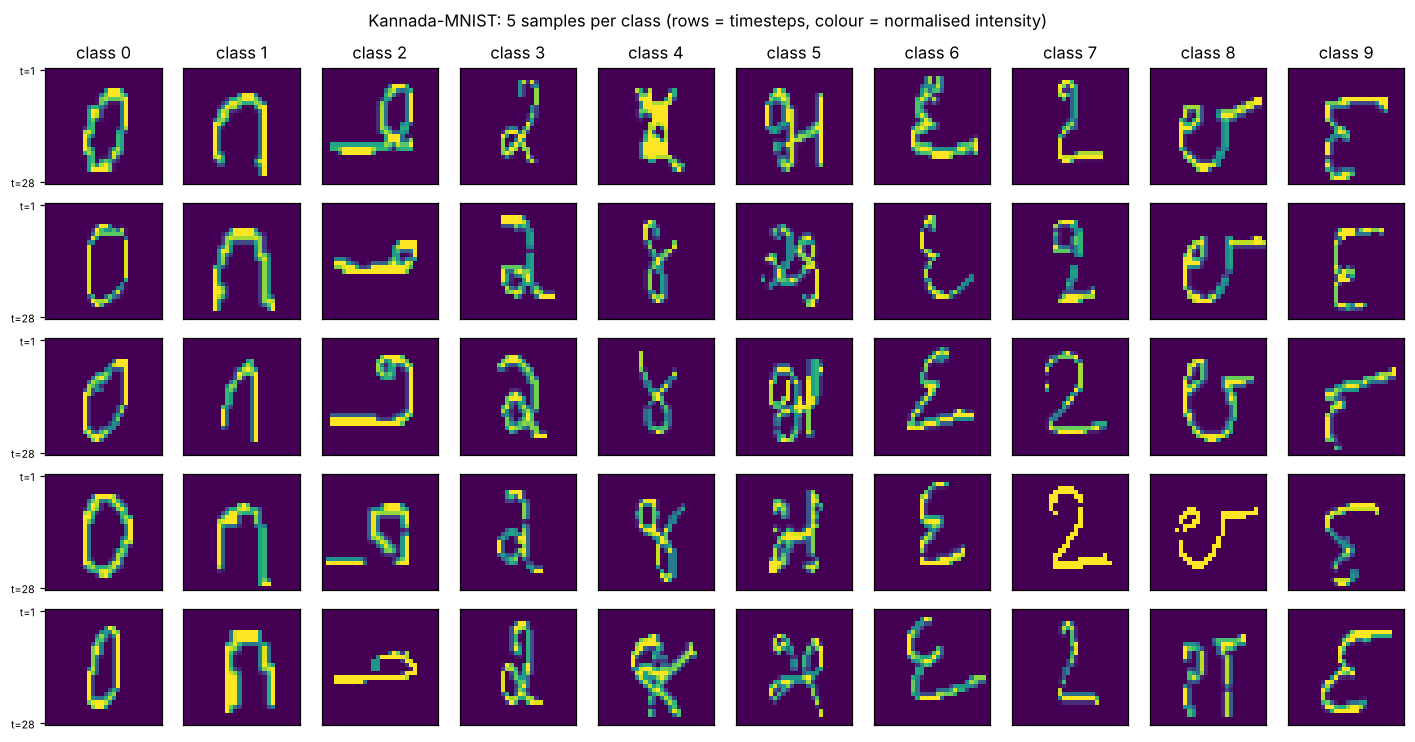

In [ ]:
fig, axes = plt.subplots(5, 10, figsize=(13, 6.8))
rng = np.random.RandomState(0)
for c in range(10):
    for r, i in enumerate(rng.choice(np.where(yk_raw == c)[0], 5, replace=False)):
        ax = axes[r, c]; ax.imshow(Xk_raw[i] / 255.0, cmap='viridis', vmin=0, vmax=1); ax.grid(False)
        ax.set_xticks([]); ax.set_yticks([0, 27] if c == 0 else []);
        if c == 0: ax.set_yticklabels(['t=1', 't=28'], fontsize=7)
        if r == 0: ax.set_title(f'class {c}')
fig.suptitle('Kannada-MNIST: 5 samples per class (rows = timesteps, colour = normalised intensity)')
fig.tight_layout(); fig.savefig(f'{FIG_DIR}/t1_samples.png', dpi=150); plt.show()

## 2.3 Hyperparameter search — RNN / LSTM / GRU (main grid)

In [ ]:
BS1 = 128
res1 = run_experiments(MAIN_GRID, 28, K_tr, K_va, K_te, BS1, 'T1')

[T1] RNN-L1-H64             params=   6666 epochs=30 conv=True  loss=0.08016 train= 97.85 val= 97.38 test= 91.20  (69s)


[T1] RNN-L1-H128            params=  21514 epochs=27 conv=True  loss=0.04483 train= 98.78 val= 98.27 test= 92.75  (93s)


[T1] RNN-L2-H64             params=  14986 epochs=36 conv=True  loss=0.04736 train= 98.83 val= 98.35 test= 93.12  (157s)


[T1] RNN-L2-H128            params=  54538 epochs=30 conv=True  loss=0.01551 train= 99.61 val= 98.87 test= 95.92  (210s)


[T1] LSTM-L1-H64            params=  24714 epochs=30 conv=True  loss=0.02147 train= 99.45 val= 98.72 test= 94.80  (95s)


...

[T1] LSTM-L2-H128           params= 214282 epochs=28 conv=True  loss=0.00373 train= 99.94 val= 99.17 test= 96.23  (622s)


[T1] GRU-L1-H64             params=  18698 epochs=29 conv=True  loss=0.03634 train= 98.99 val= 98.60 test= 93.87  (160s)


[T1] GRU-L1-H128            params=  61962 epochs=30 conv=True  loss=0.01691 train= 99.56 val= 98.78 test= 94.75  (308s)


[T1] GRU-L2-H64             params=  43658 epochs=28 conv=True  loss=0.01846 train= 99.53 val= 98.93 test= 95.30  (323s)


[T1] GRU-L2-H128            params= 161034 epochs=27 conv=True  loss=0.00620 train= 99.86 val= 99.02 test= 96.00  (604s)


## 2.4 Bonus — bidirectional networks and temporal attention pooling

In [ ]:
res1.update(run_experiments(BONUS_GRID, 28, K_tr, K_va, K_te, BS1, 'T1-bonus'))

[T1-bonus] BiLSTM-L1-H128         params= 164362 epochs=30 conv=True  loss=0.00476 train= 99.90 val= 98.98 test= 95.61  (399s)


[T1-bonus] BiGRU-L1-H128          params= 123914 epochs=28 conv=True  loss=0.01167 train= 99.70 val= 98.98 test= 95.56  (604s)


[T1-bonus] LSTM-L1-H128+Att       params=  98826 epochs=32 conv=True  loss=0.00864 train= 99.80 val= 98.77 test= 94.76  (272s)


[T1-bonus] GRU-L1-H128+Att        params=  78602 epochs=27 conv=True  loss=0.01337 train= 99.62 val= 98.90 test= 95.30  (342s)


[T1-bonus] BiGRU-L2-H128+Att      params= 486410 epochs=28 conv=True  loss=0.00245 train= 99.96 val= 99.18 test= 96.56  (1624s)


## 2.5 Average training error vs. epochs for every hyperparameter set

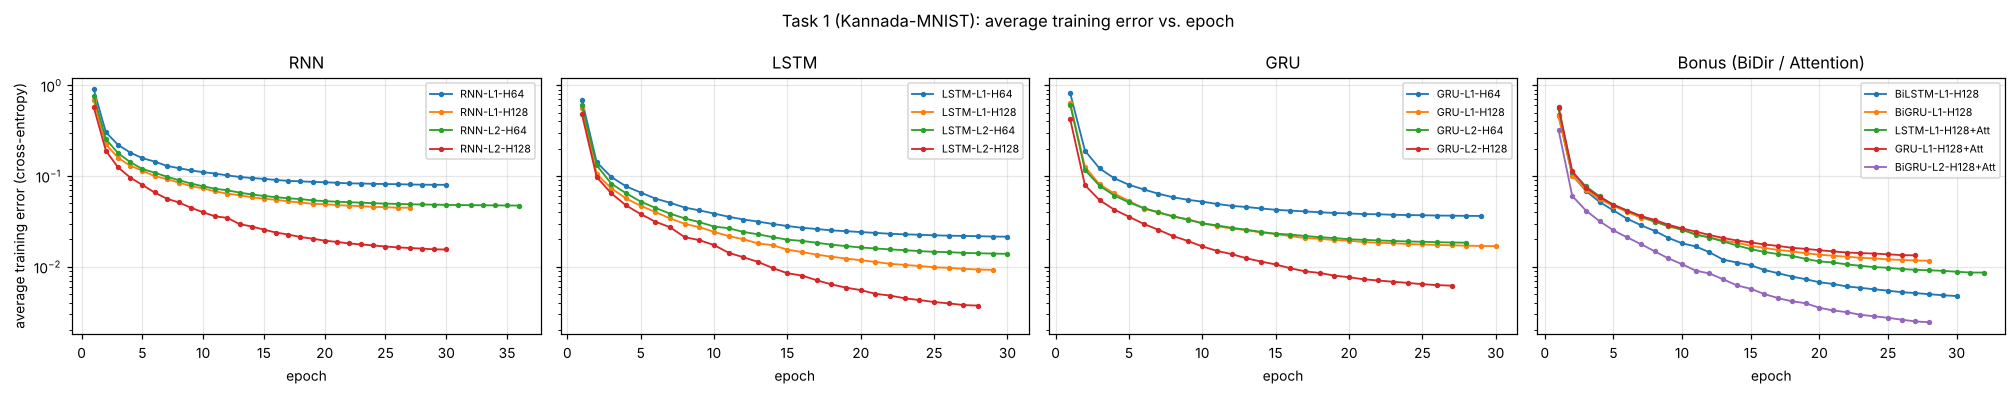

In [ ]:
def groups_of(results):
    g = {c: [n for n, r in results.items() if r['cfg']['cell'] == c and not r['cfg'].get('bidirectional')
             and not r['cfg'].get('attention')] for c in ['RNN', 'LSTM', 'GRU']}
    g['Bonus (BiDir / Attention)'] = [n for n, r in results.items()
                                      if r['cfg'].get('bidirectional') or r['cfg'].get('attention')]
    return g
plot_loss_curves(res1, 'Task 1 (Kannada-MNIST): average training error vs. epoch', 't1_loss.png', groups_of(res1))

## 2.6 Summary table — training / validation / test accuracy for every hyperparameter set

,Model,Cell,Layers,Hidden,BiDir,Attention,Params,Epochs,Converged,FinalTrainLoss,TrainAcc,ValAcc,TestAcc,TimeSec
0,RNN-L1-H64,RNN,1,64,False,False,6666,30,True,0.08016,97.85,97.38,91.20,69
1,RNN-L1-H128,RNN,1,128,False,False,21514,27,True,0.04483,98.78,98.27,92.75,93
2,RNN-L2-H64,RNN,2,64,False,False,14986,36,True,0.04736,98.83,98.35,93.12,157
3,RNN-L2-H128,RNN,2,128,False,False,54538,30,True,0.01551,99.61,98.87,95.92,210
4,LSTM-L1-H64,LSTM,1,64,False,False,24714,30,True,0.02147,99.45,98.72,94.80,95
5,LSTM-L1-H128,LSTM,1,128,False,False,82186,29,True,0.00925,99.79,98.88,95.44,191
6,LSTM-L2-H64,LSTM,2,64,False,False,57994,30,True,0.01389,99.64,98.82,95.29,181
7,LSTM-L2-H128,LSTM,2,128,False,False,214282,28,True,0.00373,99.94,99.17,96.23,622
8,GRU-L1-H64,GRU,1,64,False,False,18698,29,True,0.03634,98.99,98.60,93.87,160
9,GRU-L1-H128,GRU,1,128,False,False,61962,30,True,0.01691,99.56,98.78,94.75,308


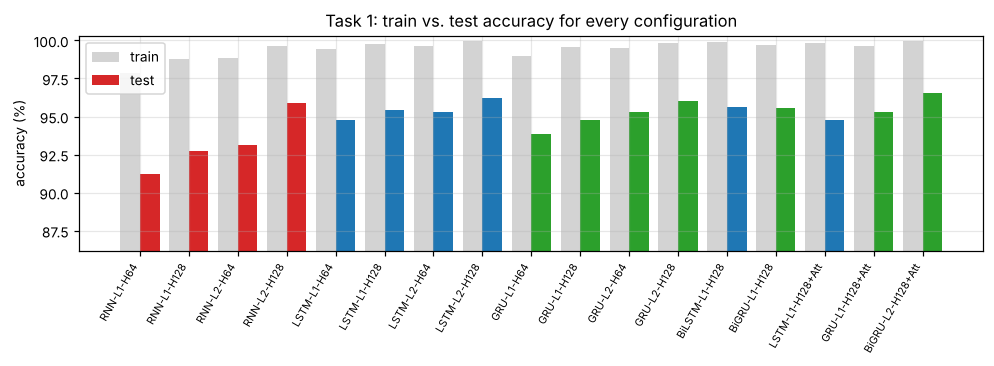

In [ ]:
df1 = summary_table(res1); df1.to_csv(f'{OUT_DIR}/task1_summary.csv', index=False)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
display(df1)
plot_acc_bars(df1, 'Task 1: train vs. test accuracy for every configuration', 't1_acc.png')

## 2.7 Best models (selected on the validation split) and confusion matrices
Model selection uses **validation accuracy only** (ties -> lower final training loss); the test split is touched once for reporting.

Best plain RNN : RNN-L2-H128      train=99.61%  val=98.87%  test=95.92%
Best plain LSTM: LSTM-L2-H128     train=99.94%  val=99.17%  test=96.23%
Best plain GRU : GRU-L2-H128      train=99.86%  val=99.02%  test=96.00%

BEST OVERALL (Task 1): BiGRU-L2-H128+Att
  final training accuracy = 99.96%
  validation accuracy     = 99.18%
  test accuracy           = 96.56%

              precision    recall  f1-score   support

           0     0.9829    0.9220    0.9515      1000
           1     0.9299    0.9810    0.9547      1000
           2     0.9930    0.9940    0.9935      1000
           3     0.9678    0.9630    0.9654      1000
           4     0.9213    0.9840    0.9516      1000
           5     0.9791    0.9370    0.9576      1000
           6     0.9611    0.9630    0.9620      1000
           7     0.9708    0.9310    0.9505      1000
           8     0.9822    0.9920    0.9871      1000
           9     0.9744    0.9890    0.9816      1000

    accuracy                         0.9

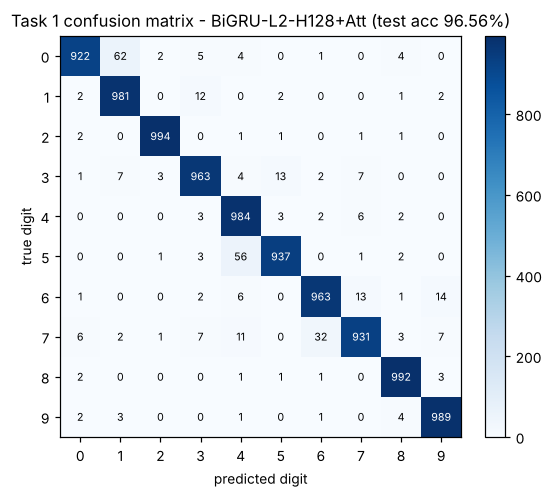

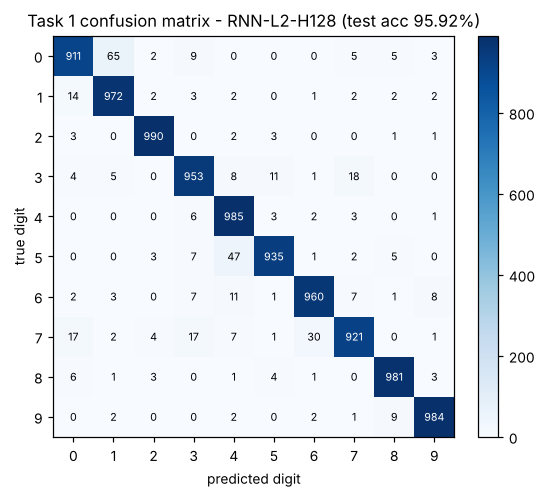

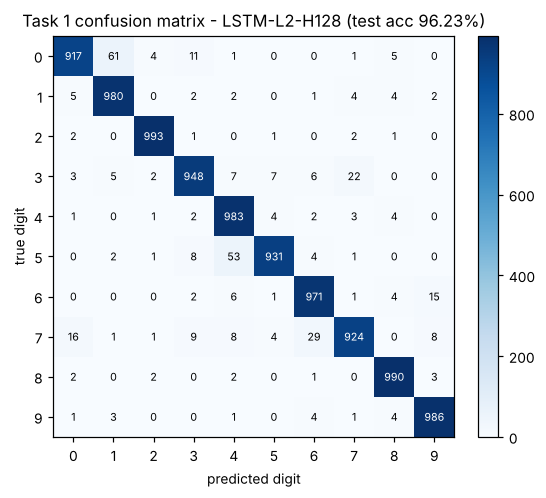

In [ ]:
def pick_best(results, pred=lambda c: True):
    names = [n for n, r in results.items() if pred(r['cfg'])]
    return max(names, key=lambda n: (results[n]['val_acc'], -results[n]['hist']['train_loss'][-1]))
plain = lambda cell: (lambda c: c['cell'] == cell and not c.get('bidirectional') and not c.get('attention'))

def report_best(results, y_test, task, prefix):
    best = {}
    for cell in ['RNN', 'LSTM', 'GRU']:
        n = pick_best(results, plain(cell)); best[cell] = n; r = results[n]
        print(f"Best plain {cell:4s}: {n:16s} train={r['train_acc']*100:.2f}%  val={r['val_acc']*100:.2f}%  test={r['test_acc']*100:.2f}%")
    n = pick_best(results); best['overall'] = n; r = results[n]
    print(f"\nBEST OVERALL ({task}): {n}\n  final training accuracy = {r['train_acc']*100:.2f}%\n"
          f"  validation accuracy     = {r['val_acc']*100:.2f}%\n  test accuracy           = {r['test_acc']*100:.2f}%\n")
    print(classification_report(y_test, r['test_pred'], digits=4))
    cms = {}
    for key in ['overall', 'RNN', 'LSTM']:
        nm = best[key]
        cms[key] = plot_cm(y_test, results[nm]['test_pred'],
                           f"{task} confusion matrix - {nm} (test acc {results[nm]['test_acc']*100:.2f}%)",
                           f'{prefix}_cm_{key}.png')
    return best, cms
best1, cms1 = report_best(res1, yk_te_raw, 'Task 1', 't1')

## 2.8 Extra: generalisation of the best model to Dig-MNIST (different writers, out-of-distribution)

In [ ]:
dig_acc = None
if dig_raw is not None:
    m = build(res1[best1['overall']]['cfg'], 28, res1[best1['overall']]['state'])
    _, dig_acc, _ = evaluate(m, to_seq(dig_raw[0]), torch.tensor(dig_raw[1].astype(np.int64)))
    print(f"Dig-MNIST accuracy of {best1['overall']}: {dig_acc*100:.2f}%  (in-distribution test: {res1[best1['overall']]['test_acc']*100:.2f}%)")

Dig-MNIST accuracy of BiGRU-L2-H128+Att: 73.32%  (in-distribution test: 96.56%)


## 2.9 Gradient flow — Vanilla RNN vs LSTM vs GRU
For the 1-layer, 128-unit models (classifier reads the final hidden state) we measure
`|| dLoss/dx_t ||` for every timestep t, **at initialisation** and **after training**.
The gradient that reaches an early row has travelled back through all later recurrent steps, so the
slope of this curve shows how quickly the error signal vanishes with temporal distance.
We also plot the mean (pre-clipping) parameter-gradient norm per epoch recorded during training.

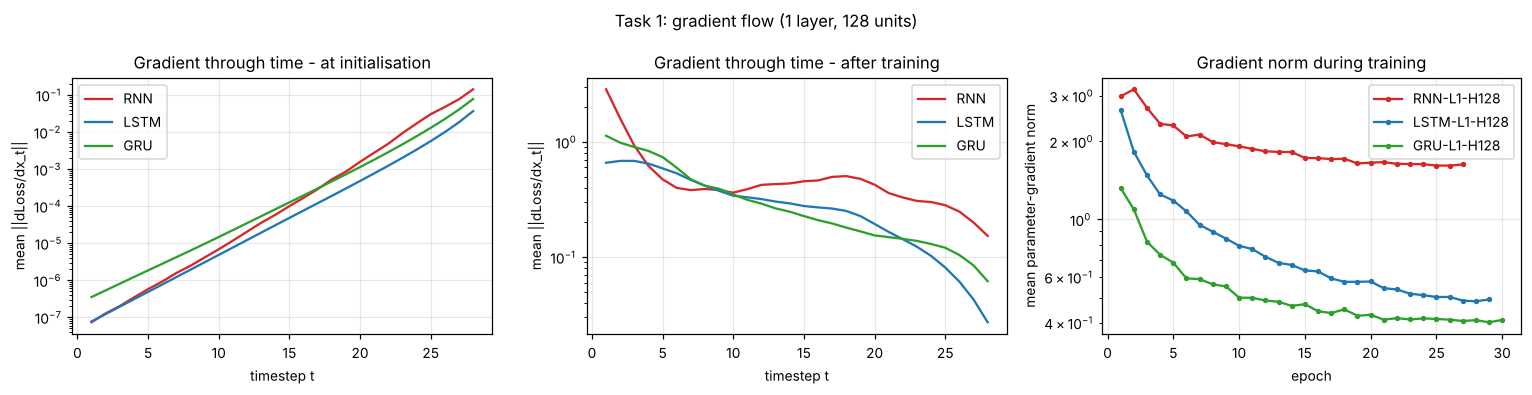

RNN  ratio earliest/latest gradient:  init=5.169e-07   trained=1.869e+01
LSTM ratio earliest/latest gradient:  init=2.119e-06   trained=2.421e+01
GRU  ratio earliest/latest gradient:  init=4.539e-06   trained=1.829e+01


In [ ]:
def gradient_flow_figure(results, in_dim, te, title, fname, last_k=None, xlabel='timestep t'):
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.6)); flow = {}
    for cell in ['RNN', 'LSTM', 'GRU']:
        c = dict(cell=cell, layers=1, hidden=128); n = cfg_name(c)
        set_seed(); g0 = grad_vs_time(build(c, in_dim), te[0], te[1], te[2], last_k=last_k)
        g1 = grad_vs_time(build(c, in_dim, results[n]['state']), te[0], te[1], te[2], last_k=last_k)
        flow[cell] = dict(init=g0.tolist(), trained=g1.tolist())
        x = np.arange(1, len(g0) + 1) if last_k is None else np.arange(-len(g0) + 1, 1)
        axes[0].plot(x, g0, color=CELL_COLORS[cell], label=cell)
        axes[1].plot(x, g1, color=CELL_COLORS[cell], label=cell)
        axes[2].plot(range(1, results[n]['hist']['epochs'] + 1), results[n]['hist']['grad_norm'],
                     color=CELL_COLORS[cell], marker='o', ms=2.5, label=n)
    for ax, t in zip(axes[:2], ['at initialisation', 'after training']):
        ax.set_yscale('log'); ax.set_xlabel(xlabel); ax.set_ylabel('mean ||dLoss/dx_t||'); ax.set_title('Gradient through time - ' + t); ax.legend()
    axes[2].set_yscale('log'); axes[2].set_xlabel('epoch'); axes[2].set_ylabel('mean parameter-gradient norm'); axes[2].set_title('Gradient norm during training'); axes[2].legend()
    fig.suptitle(title); fig.tight_layout(); fig.savefig(f'{FIG_DIR}/{fname}', dpi=150); plt.show()
    for cell, f in flow.items():
        print(f"{cell:4s} ratio earliest/latest gradient:  init={f['init'][0]/f['init'][-1]:.3e}   trained={f['trained'][0]/f['trained'][-1]:.3e}")
    return flow
flow1 = gradient_flow_figure(res1, 28, K_te, 'Task 1: gradient flow (1 layer, 128 units)', 't1_gradflow.png')

## 2.10 Extra: what does temporal attention look at?
Attention weights over the 28 rows (timesteps) of the GRU+attention model, shown beside each image.

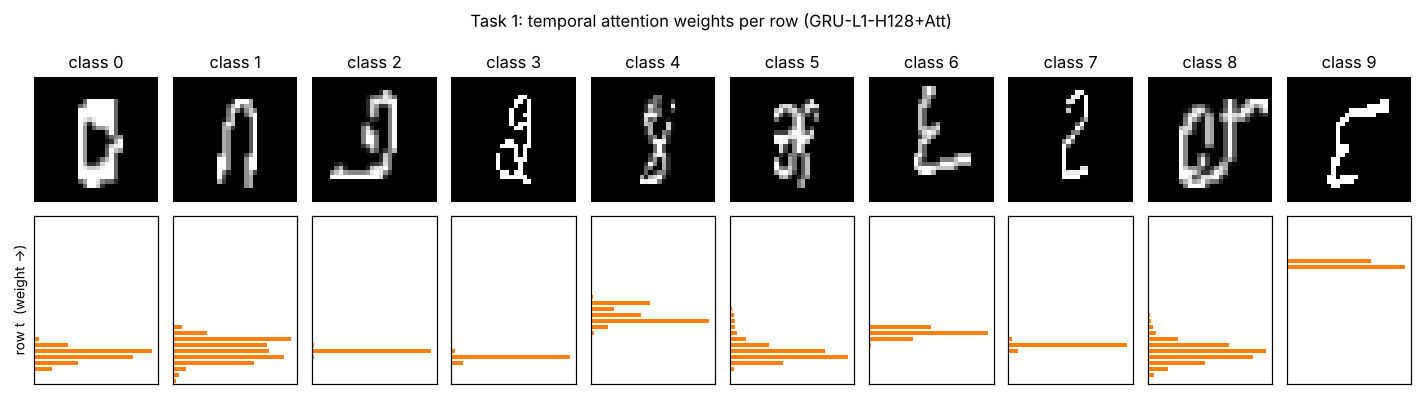

In [ ]:
att_name = cfg_name(dict(cell='GRU', layers=1, hidden=128, attention=True))
m = build(res1[att_name]['cfg'], 28, res1[att_name]['state']); m.eval()
fig, axes = plt.subplots(2, 10, figsize=(13, 3.6), gridspec_kw={'height_ratios': [1, 1]})
for c in range(10):
    i = int(np.where(yk_te_raw == c)[0][0]); x = K_te[0][i:i + 1].to(DEVICE)
    with torch.no_grad(): m(x)
    a = m.last_att[0].cpu().numpy()
    axes[0, c].imshow(K_te[0][i], cmap='gray'); axes[0, c].set_title(f'class {c}'); axes[0, c].axis('off')
    axes[1, c].barh(np.arange(28), a, color='tab:orange'); axes[1, c].invert_yaxis()
    axes[1, c].set_yticks([]); axes[1, c].set_xticks([]); axes[1, c].set_ylim(27.5, -0.5)
axes[1, 0].set_ylabel('row t  (weight ->)')
fig.suptitle(f'Task 1: temporal attention weights per row ({att_name})'); fig.tight_layout()
fig.savefig(f'{FIG_DIR}/t1_attention.png', dpi=150); plt.show()